# Ship of Theseus corpus: lexical vs semantic decay, style vs content

Implements `docs/sot_analysis_plan.md` on the published English Ship of Theseus corpus (Tripto et al., 2024). Nothing is generated here: every text is from the corpus. This notebook produces the three figures in the final report.

1. **Data:** 7 datasets, 7 sources, 19,342 originals (T0), and 7 paraphraser variants × 3 chained rounds (T1–T3).
2. **Lexical vs semantic metrics:** BLEU, ROUGE-L and word retention (the "planks") vs BERTScore and a sentence-embedding cosine (the "hull"), T0 → T1/T2/T3, for ChatGPT, PaLM, Dipper and Pegasus (`decay_curves.png`).
3. **Style vs content decay:** does the meaning stay intact while the words and the style are replaced? (`style_vs_content.png`, `style_blocks_and_sources.png`)

In [1]:
import shutil
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pilot.config import ROOT, load_config, set_seeds
from pilot.metrics import DATASETS, bootstrap_mean_ci, load_corpus, load_reference

warnings.filterwarnings("ignore", category=FutureWarning)
cfg = load_config()
set_seeds(cfg["seed"])
SOT, DERIVED = cfg["paths"]["sot"], cfg["paths"]["derived"]
OUT = cfg["paths"]["results"] / "sot_analysis"
OUT.mkdir(parents=True, exist_ok=True)

# Paraphrasers: the four primary variants, plus the intensity variants of Dipper and Pegasus.
PRIMARY = ["chatgpt", "palm", "dipper", "pegasus(full)"]
LABEL = {"chatgpt": "ChatGPT", "palm": "PaLM", "dipper": "Dipper", "pegasus(full)": "Pegasus",
         "dipper(low)": "Dipper (low)", "dipper(high)": "Dipper (high)", "pegasus(slight)": "Pegasus (slight)"}

# Categorical palette (validated: adjacent CVD ΔE 9.1, normal-vision 22.9; aqua/yellow < 3:1 contrast,
# so every chart carries direct labels and a CSV table). Color follows the paraphraser, in fixed order.
COLOR = {"chatgpt": "#2a78d6", "palm": "#eb6834", "dipper": "#1baf7a", "pegasus(full)": "#eda100"}
MARKER = {"chatgpt": "o", "palm": "s", "dipper": "^", "pegasus(full)": "D"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight", "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.labelsize": 9, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "lines.linewidth": 2, "lines.markersize": 6,
    "legend.frameon": False, "legend.fontsize": 8, "font.size": 9,
})

def label_ends(ax, items, x, min_gap=None, fmt="{label} {y:.2f}"):
    """Direct labels at line ends, nudged apart vertically so they never collide.
    items: list of (label, y, color-or-None)."""
    lo, hi = ax.get_ylim()
    gap = min_gap if min_gap is not None else 0.045 * (hi - lo)
    placed = []
    for label, y, _ in sorted(items, key=lambda t: t[1]):
        pos = max(y, placed[-1] + gap) if placed else y
        placed.append(pos)
        ax.annotate(fmt.format(label=label, y=y), (x, y), xytext=(x + 0.12, pos), textcoords="data",
                    va="center", fontsize=8, color=INK,
                    arrowprops=dict(arrowstyle="-", color=GRID, linewidth=0.6) if abs(pos - y) > 1e-9 else None)


def save(fig, name, table=None):
    fig.savefig(OUT / f"{name}.png")
    if table is not None:
        table.to_csv(OUT / f"{name}.csv", index=False)

print("results ->", OUT.relative_to(ROOT))

results -> results/sot_analysis


## 1. Data

All 7 datasets are copied from the upstream clone into git-ignored `data/sot/` (read-only), then loaded as one long table with one row per text: dataset, source, key, variant, round (0 = T0) and text. `train_datasets/` (never paraphrased, disjoint keys) is loaded as the **reference set**, used for normalization floors and for fitting style features.

In [2]:
for ds in DATASETS:
    for rel in (f"paraphrased_datasets/{ds}_paraphrased.csv", f"train_datasets/{ds}_train.csv"):
        dst = SOT / rel
        if not dst.exists():
            dst.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(cfg["paths"]["corpus_src"] / rel, dst)
            dst.chmod(0o444)

corpus = load_corpus(SOT)
reference = load_reference(SOT)
corpus["words"] = corpus.text.str.split().str.len()
reference["words"] = reference.text.str.split().str.len()

originals = corpus[corpus["round"] == 0]
summary = pd.DataFrame({
    "originals": originals.groupby("dataset").size(),
    "keys": originals.groupby("dataset").key.nunique(),
    "paraphrased_rows": corpus[corpus["round"] > 0].groupby("dataset").size(),
    "reference_texts": reference.groupby("dataset").size(),
    "median_T0_words": originals.groupby("dataset").words.median(),
})
summary.loc["total"] = [summary.originals.sum(), summary["keys"].sum(), summary.paraphrased_rows.sum(),
                        summary.reference_texts.sum(), originals.words.median()]
print(f"{len(corpus):,} corpus rows | {corpus.source.nunique()} sources | variants: {sorted(corpus.variant.unique())}")
summary.astype(int)

420,012 corpus rows | 7 sources | variants: ['chatgpt', 'dipper', 'dipper(high)', 'dipper(low)', 'original', 'palm', 'pegasus(full)', 'pegasus(slight)']


,originals,keys,paraphrased_rows,reference_texts,median_T0_words
dataset,,,,,
cmv,1626,256,33779,1666,295
eli5,3160,475,66110,3181,160
sci_gen,2797,471,57369,2780,181
tldr,2444,382,51075,2559,113
wp,2768,469,55649,2754,330
xsum,3227,476,67161,3243,162
yelp,3320,491,69527,3344,121
total,19342,3020,400670,19527,172


In [3]:
ID = ["dataset", "source", "key"]
chains = corpus[corpus["round"] > 0]

## 2. Lexical vs semantic metrics

**Scope.** PaLM chains are often incomplete (only 87.5% of originals reach T3), so the comparison uses **completer originals only**: those that all four primary paraphrasers (ChatGPT, PaLM, Dipper, Pegasus-full) carry to T3, and that have a T0 text. Every paraphraser is then scored on exactly the same texts. `SCOPE = "full"` keeps all 16,682 of them; `SCOPE = "sample"` draws 60 keys per dataset (seeded) and keeps every completer original of those keys.

At full scope the slow scores come from background scripts (`scripts/score_lexical.py full`, `scripts/score_semantic.py`, `scripts/style_features.py`), which write the caches the cells below read.

**Pairs.**
- *Cumulative:* T0 vs Tn, n = 1, 2, 3 (the decay curve).
- *Step:* Tn−1 vs Tn, n = 2, 3 (how much each extra round changes; for n = 1, step = cumulative).
- *Floor:* 200 random pairs of unrelated reference texts per dataset (different keys).

Scores are cached to `data/derived/sot_pairs_*.parquet`.

In [4]:
# SCOPE = "sample": 60 keys per dataset (fast; the original analysis).
# SCOPE = "full":   every completer original (the slow parts run as background scripts; see §2 notes).
SCOPE = "full"
N_KEYS = 60
VARIANTS = PRIMARY + ["dipper(low)", "dipper(high)", "pegasus(slight)"]
KEYS = ID + ["variant", "round", "kind"]
texts = corpus.set_index(ID + ["variant", "round"]).text  # (dataset, source, key, variant, round) -> text

reach_t3 = chains[(chains["round"] == 3) & chains.variant.isin(PRIMARY)].groupby(ID).variant.nunique()
completers = reach_t3[reach_t3 == len(PRIMARY)].reset_index()[ID]
# One chain (xsum / OpenAI / xsum-492) has all its paraphrases but no T0 text in the corpus; nothing to compare against.
completers = completers.merge(corpus.loc[corpus["round"] == 0, ID], on=ID)
if SCOPE == "full":
    sample = completers.copy()
else:
    rng = np.random.default_rng([cfg["seed"], 31])
    sample_keys = pd.concat([
        part.drop_duplicates("key").sample(N_KEYS, random_state=int(rng.integers(1e9)))[["dataset", "key"]]
        for _, part in completers.groupby("dataset")
    ])
    sample = completers.merge(sample_keys, on=["dataset", "key"])

# Pairs (cumulative T0 vs Tn, step Tn-1 vs Tn), built by the same function the background scripts use.
from pilot.metrics import build_pairs
pairs = build_pairs(corpus, sample, VARIANTS)

rng_floor = np.random.default_rng([cfg["seed"], 32])
floor_rows = []
for ds, part in reference.groupby("dataset"):
    for _ in range(200):
        a, b = part.sample(2, random_state=int(rng_floor.integers(1e9))).itertuples()
        if a.key != b.key:
            floor_rows.append({"dataset": ds, "ref": a.text, "hyp": b.text})
floors = pd.DataFrame(floor_rows)

# The background scoring scripts (scripts/score_semantic.py, scripts/style_features.py) read these.
SAMPLE_PATH, FLOORS_PATH = DERIVED / "sot_sample.parquet", DERIVED / "sot_floors.parquet"
sample.to_parquet(SAMPLE_PATH, index=False)
floors.assign(floor_id=range(len(floors))).to_parquet(FLOORS_PATH, index=False)

print(f"SCOPE={SCOPE} | completer originals: {len(completers):,} of {len(originals):,} | analysed: {len(sample):,} originals "
      f"on {sample[['dataset', 'key']].drop_duplicates().shape[0]:,} keys | pairs: {len(pairs):,} | floor pairs: {len(floors)}")
sample.groupby(["dataset"]).size().to_frame("originals").T

SCOPE=full | completer originals: 16,682 of 19,342 | analysed: 16,682 originals on 2,996 keys | pairs: 583,870 | floor pairs: 1396


dataset,cmv,eli5,sci_gen,tldr,wp,xsum,yelp
originals,1490,3066,1634,2333,1922,3005,3232


In [5]:
import time

from pilot.metrics import score_lexical_chunked

LEX_CACHE = DERIVED / f"sot_pairs_lexical_{SCOPE}.parquet"  # one file per scope
FLOOR_LEX_CACHE = DERIVED / "sot_floors_lexical.parquet"

# Chunked, bounded-memory scoring: feeding all 580k full-scope pairs to a process pool at once
# exhausted memory and killed the kernel. SCOPE="full" comes from `python scripts/score_lexical.py`.
started = time.time()
if not LEX_CACHE.exists():
    if SCOPE == "full":
        raise RuntimeError("run `python scripts/score_lexical.py full` in the background, then re-run this cell")
    score_lexical_chunked(pairs, LEX_CACHE)
if not FLOOR_LEX_CACHE.exists():
    score_lexical_chunked(floors.assign(source="", key="", variant="", round=0, kind="floor"), FLOOR_LEX_CACHE)
lex = pd.read_parquet(LEX_CACHE)
floor_lex = pd.read_parquet(FLOOR_LEX_CACHE)
assert len(lex) == len(pairs) and len(floor_lex) == len(floors)
print(f"lexical scores: {len(lex):,} pairs + {len(floor_lex):,} floor pairs in {time.time() - started:.0f}s")
LEXICAL = ["bleu", "rouge1", "rouge2", "rougeL", "word_retention"]
lex[lex.kind == "cumulative"].groupby(["variant", "round"])[LEXICAL].mean().round(3)

lexical scores: 583,870 pairs + 1,396 floor pairs in 0s


bleu  rouge1  rouge2  rougeL  word_retention
variant         round                                               
chatgpt         1      0.234   0.613   0.338   0.504           0.547
                2      0.212   0.591   0.310   0.469           0.528
                3      0.177   0.556   0.269   0.429           0.479
dipper          1      0.196   0.607   0.303   0.372           0.463
                2      0.113   0.519   0.203   0.313           0.346
                3      0.079   0.469   0.158   0.254           0.286
dipper(high)    1      0.016   0.242   0.029   0.127           0.052
                2      0.008   0.191   0.017   0.104           0.029
                3      0.005   0.152   0.012   0.088           0.019
dipper(low)     1      0.519   0.822   0.650   0.709           0.758
                2      0.396   0.754   0.537   0.621           0.667
                3      0.330   0.711   0.473   0.560           0.612
palm            1      0.429   0.709   0.544   0.647           0.658
                2      0.349   0.650   0.461   0.574           0.586
                3      0.313   0.623   0.424   0.540           0.554
pegasus(full)   1      0.424   0.781   0.610   0.672           0.688
                2      0.313   0.696   0.495   0.586           0.582
                3      0.267   0.657   0.449   0.540           0.537
pegasus(slight) 1      0.843   0.941   0.898   0.916           0.919
                2      0.732   0.896   0.821   0.853           0.857
                3      0.646   0.859   0.759   0.802           0.806

In [6]:
import importlib

import pilot.metrics
importlib.reload(pilot.metrics)
from pilot.metrics import chain_jobs, score_semantic

SEM_CACHE, FLOOR_SEM_CACHE = DERIVED / "sot_pairs_semantic.parquet", DERIVED / "sot_floors_semantic.parquet"

def floor_jobs(frame):
    for r in frame.assign(floor_id=range(len(frame))).itertuples(index=False):
        yield {"dataset": r.dataset, "floor_id": r.floor_id}, [r.ref, r.hyp], [(0, 1, {"kind": "floor"})]

# BERTScore + sentence-embedding cosine. The cache is keyed by original and resumable, and a full-corpus
# cache also serves the sample. SCOPE="sample" computes missing scores here (about 1-2 h on MPS);
# SCOPE="full" (about 9 h) must come from `python scripts/score_semantic.py`, never from the kernel.
def semantic_missing():
    if not (SEM_CACHE.exists() and FLOOR_SEM_CACHE.exists()):
        return len(sample)
    cached = pd.read_parquet(SEM_CACHE, columns=ID).drop_duplicates()
    return len(sample.merge(cached, on=ID, how="left", indicator=True).query("_merge == 'left_only'"))

missing = semantic_missing()
if missing and SCOPE == "full":
    raise RuntimeError(f"{missing:,} originals lack semantic scores: run `python scripts/score_semantic.py` "
                       "in the background (resumable), then re-run from this cell")
if missing:
    score_semantic(chain_jobs(sample, texts, VARIANTS, ID), SEM_CACHE, ID)
    score_semantic(floor_jobs(floors), FLOOR_SEM_CACHE, ["dataset", "floor_id"])
sem = pd.read_parquet(SEM_CACHE).merge(sample, on=ID)  # only the originals in this scope
floor_sem = pd.read_parquet(FLOOR_SEM_CACHE)
print(f"semantic scores: {len(sem):,} pairs + {len(floor_sem):,} floor pairs")
sem[sem.kind == "cumulative"].groupby(["variant", "round"])[["bertscore_f", "bertscore_p", "bertscore_r", "sbert_cos"]].mean().round(3)

semantic scores: 583,870 pairs + 1,396 floor pairs


bertscore_f  bertscore_p  bertscore_r  sbert_cos
variant         round                                                  
chatgpt         1            0.563        0.604        0.522      0.894
                2            0.519        0.563        0.476      0.881
                3            0.488        0.533        0.444      0.872
dipper          1            0.441        0.464        0.417      0.825
                2            0.346        0.383        0.308      0.775
                3            0.279        0.325        0.233      0.732
dipper(high)    1           -0.132       -0.116       -0.150      0.177
                2           -0.148       -0.110       -0.188      0.112
                3           -0.150       -0.092       -0.208      0.083
dipper(low)     1            0.721        0.742        0.700      0.921
                2            0.646        0.680        0.612      0.897
                3            0.599        0.642        0.556      0.881
palm            1            0.655        0.713        0.601      0.894
                2            0.594        0.659        0.532      0.874
                3            0.565        0.633        0.500      0.865
pegasus(full)   1            0.603        0.677        0.534      0.880
                2            0.509        0.598        0.427      0.847
                3            0.467        0.561        0.379      0.829
pegasus(slight) 1            0.880        0.902        0.859      0.957
                2            0.803        0.839        0.769      0.935
                3            0.745        0.792        0.700      0.918

In [7]:
import json

importlib.reload(pilot.metrics)
from sklearn.feature_extraction.text import TfidfVectorizer

from pilot.metrics import extract_style, reference_subset, text_hash, top_function_words

STYLE_CACHE, FW_PATH = DERIVED / "sot_style_features.parquet", DERIVED / "sot_function_words.json"
# Per-pair style scores take ~15 min at full scope, so they are cached like the lexical scores.
STYLE_SCORES = DERIVED / f"sot_pairs_style_{SCOPE}.parquet"
FLOOR_STYLE_SCORES = DERIVED / f"sot_floors_style_{SCOPE}.parquet"


def compute_style_scores():
    # The reference subset fixes the function-word list, the z-scoring and the char n-gram vocabulary,
    # so no paraphrase output influences how style is measured.
    ref_sub = reference_subset(reference, 300, cfg["seed"])
    unique_texts = pd.Index(pd.unique(pd.concat([pairs.ref, pairs.hyp, floors.ref, floors.hyp, ref_sub.text])))

    # spaCy is slow; scripts/style_features.py computes the same cache with multiprocessing (which deadlocks
    # inside Jupyter on macOS). Without a cache, fall back to single-process extraction here.
    if STYLE_CACHE.exists():
        feats = pd.read_parquet(STYLE_CACHE).drop_duplicates("text_hash").set_index("text_hash")
    else:
        function_words = top_function_words(ref_sub.text)
        feats = extract_style(list(unique_texts), function_words).set_index("text_hash")
        feats.reset_index().to_parquet(STYLE_CACHE, index=False); FW_PATH.write_text(json.dumps(function_words))
    hashes = [text_hash(t) for t in unique_texts]
    assert set(hashes) <= set(feats.index), "style cache is missing texts; re-run scripts/style_features.py"
    feats = feats.loc[hashes].reset_index(drop=True)
    text_id = pd.Series(range(len(unique_texts)), index=unique_texts)

    # z-score each feature on the reference subset; style similarity = mean of the per-block cosines,
    # so the 100 function-word dimensions can't drown out the 6 surface or 10 punctuation features.
    ref_ids = text_id[ref_sub.text].to_numpy()
    mu, sd = feats.iloc[ref_ids].mean(), feats.iloc[ref_ids].std().replace(0, 1e-9)
    Z = ((feats - mu) / sd).fillna(0).to_numpy()
    cols = list(feats.columns)
    blocks = {
        "surface": [cols.index(c) for c in ["sent_len_mean", "sent_len_sd", "word_len_mean", "mattr", "cap_rate", "dep_depth_mean"]],
        "punctuation": [i for i, c in enumerate(cols) if c.startswith("punct_")],
        "function_words": [i for i, c in enumerate(cols) if c.startswith("fw_")],
        "syntax_pos": [i for i, c in enumerate(cols) if c.startswith("pos_")],
    }

    def block_cos(a, b, idx):
        x, y = Z[a][:, idx], Z[b][:, idx]
        return (x * y).sum(1) / (np.linalg.norm(x, axis=1) * np.linalg.norm(y, axis=1) + 1e-12)

    char_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=3, sublinear_tf=True).fit(ref_sub.text)

    def style_scores(frame, chunk=20_000):
        """Per-pair style similarities, in chunks: a char n-gram matrix over all ~366k full-scope texts would be ~9 GB.
        TfidfVectorizer rows are L2-normalized, so the row-wise dot product is the cosine."""
        parts = []
        for s in range(0, len(frame), chunk):
            f = frame.iloc[s:s + chunk]
            a, b = text_id[f.ref].to_numpy(), text_id[f.hyp].to_numpy()
            out = {f"style_{k}": block_cos(a, b, idx) for k, idx in blocks.items()}
            out["style"] = np.mean(list(out.values()), axis=0)
            out["style_charngram"] = np.asarray(char_vec.transform(f.ref).multiply(char_vec.transform(f.hyp)).sum(axis=1)).ravel()
            parts.append(pd.DataFrame(out))
        return pd.concat(parts, ignore_index=True)

    print(f"style features: {len(cols)} | blocks: { {k: len(v) for k, v in blocks.items()} }")
    # Keys come from `pairs` itself (row-aligned with the scores), never from another cache's row order.
    style = pd.concat([pairs[KEYS].reset_index(drop=True), style_scores(pairs.reset_index(drop=True))], axis=1)
    floor_style = pd.concat([floor_lex[["dataset"]].reset_index(drop=True), style_scores(floors.reset_index(drop=True))], axis=1)
    return style, floor_style


if STYLE_SCORES.exists() and FLOOR_STYLE_SCORES.exists():
    style, floor_style = pd.read_parquet(STYLE_SCORES), pd.read_parquet(FLOOR_STYLE_SCORES)
    # The cache must cover exactly the current pairs (it is merged on keys downstream, never by position).
    assert len(style) == len(pairs) and style[KEYS].merge(pairs[KEYS]).shape[0] == len(pairs), "stale style cache; delete it"
else:
    style, floor_style = compute_style_scores()
    style.to_parquet(STYLE_SCORES, index=False); floor_style.to_parquet(FLOOR_STYLE_SCORES, index=False)
print(f"style scores: {len(style):,} pairs + {len(floor_style):,} floor pairs")
style[style.kind == "cumulative"].groupby(["variant", "round"])[["style", "style_charngram"]].mean().round(3)

style scores: 583,870 pairs + 1,396 floor pairs


style  style_charngram
variant         round                        
chatgpt         1      0.584            0.679
                2      0.546            0.661
                3      0.512            0.627
dipper          1      0.592            0.617
                2      0.509            0.529
                3      0.458            0.478
dipper(high)    1      0.093            0.196
                2      0.064            0.162
                3      0.047            0.141
dipper(low)     1      0.789            0.828
                2      0.727            0.772
                3      0.690            0.738
palm            1      0.713            0.770
                2      0.653            0.716
                3      0.626            0.692
pegasus(full)   1      0.708            0.807
                2      0.617            0.744
                3      0.576            0.713
pegasus(slight) 1      0.941            0.954
                2      0.890            0.919
                3      0.845            0.889

### 2.1 One scale for every metric: retained share

Each metric is normalized per dataset against its **floor**, the mean score of 200 unrelated reference-text pairs from that dataset:

$$\text{retained} = \frac{s - \text{floor}}{1 - \text{floor}}$$

Every metric scores 1 for identical texts (BLEU, ROUGE, word retention, baseline-rescaled BERTScore, cosine similarities), so **retained = 1 means identical to T0 and 0 means no closer than a random text from the same dataset**. Lexical, semantic and style decay can then be compared on one axis, which raw scores don't allow: raw BERTScore and raw BLEU live on very different ranges.

In [8]:
KEYS = ID + ["variant", "round", "kind"]
SEMANTIC = ["bertscore_f", "bertscore_p", "bertscore_r", "sbert_cos"]
STYLE = ["style", "style_surface", "style_punctuation", "style_function_words", "style_syntax_pos", "style_charngram"]
METRICS = LEXICAL + SEMANTIC + STYLE
NAME = {"bleu": "BLEU", "rouge1": "ROUGE-1", "rouge2": "ROUGE-2", "rougeL": "ROUGE-L", "word_retention": "Word retention",
        "bertscore_f": "BERTScore F1", "bertscore_p": "BERTScore precision", "bertscore_r": "BERTScore recall",
        "sbert_cos": "Sentence-embedding cosine", "style": "Style (stylometric)", "style_charngram": "Style (char n-grams)",
        "style_surface": "Style: surface", "style_punctuation": "Style: punctuation",
        "style_function_words": "Style: function words", "style_syntax_pos": "Style: syntax/POS"}
FAMILY = {**{m: "lexical" for m in LEXICAL}, **{m: "semantic" for m in SEMANTIC}, **{m: "style" for m in STYLE}}

scores = (lex.merge(sem, on=KEYS, how="left", validate="1:1")
             .merge(style, on=KEYS, how="left", validate="1:1"))
assert len(scores) == len(lex), "pairs lost in the merge"
missing = scores[METRICS].isna().sum()
# Undefined, not missing: word retention when the reference has no content words, BERTScore precision
# when the output is empty (degenerate outputs). Left as NaN; the bootstrap skips them.
assert missing.sum() < 0.001 * len(scores), f"too many undefined scores: {missing[missing > 0].to_dict()}"
print("undefined scores (degenerate outputs, left as NaN):", missing[missing > 0].to_dict())
p = pairs.reset_index(drop=True)
scores = scores.merge(p.assign(len_ratio=p.hyp.str.split().str.len() / p.ref.str.split().str.len())[KEYS + ["len_ratio"]],
                      on=KEYS, validate="1:1")

floor_all = pd.concat([floor_lex.assign(floor_id=range(len(floor_lex))).merge(floor_sem, on=["dataset", "floor_id"]),
                       floor_style.drop(columns="dataset")], axis=1)
floor = floor_all.groupby("dataset")[METRICS].mean()
for m in METRICS:
    f = scores.dataset.map(floor[m])
    scores[f"{m}_ret"] = (scores[m] - f) / (1 - f)

floor.round(3).to_csv(OUT / "floors_by_dataset.csv")
print(f"{len(scores):,} scored pairs | floors (mean over datasets):")
floor.mean().round(3).to_frame("floor").T

undefined scores (degenerate outputs, left as NaN): {'word_retention': 70, 'bertscore_f': 21, 'bertscore_p': 15, 'bertscore_r': 6}
583,870 scored pairs | floors (mean over datasets):


,bleu,rouge1,rouge2,rougeL,word_retention,bertscore_f,bertscore_p,bertscore_r,sbert_cos,style,style_surface,style_punctuation,style_function_words,style_syntax_pos,style_charngram
floor,0.009,0.191,0.017,0.096,0.06,-0.146,-0.142,-0.151,0.153,0.157,0.215,0.138,0.076,0.198,0.193


### 2.2 Decay curves: planks vs hull

Mean retained share at T0–T3 for the four paraphrasers, with 95% bootstrap CIs (1,000 resamples of keys). The top row is lexical (the planks), the bottom row semantic and style. The table behind the figure is `decay_curves.csv`.

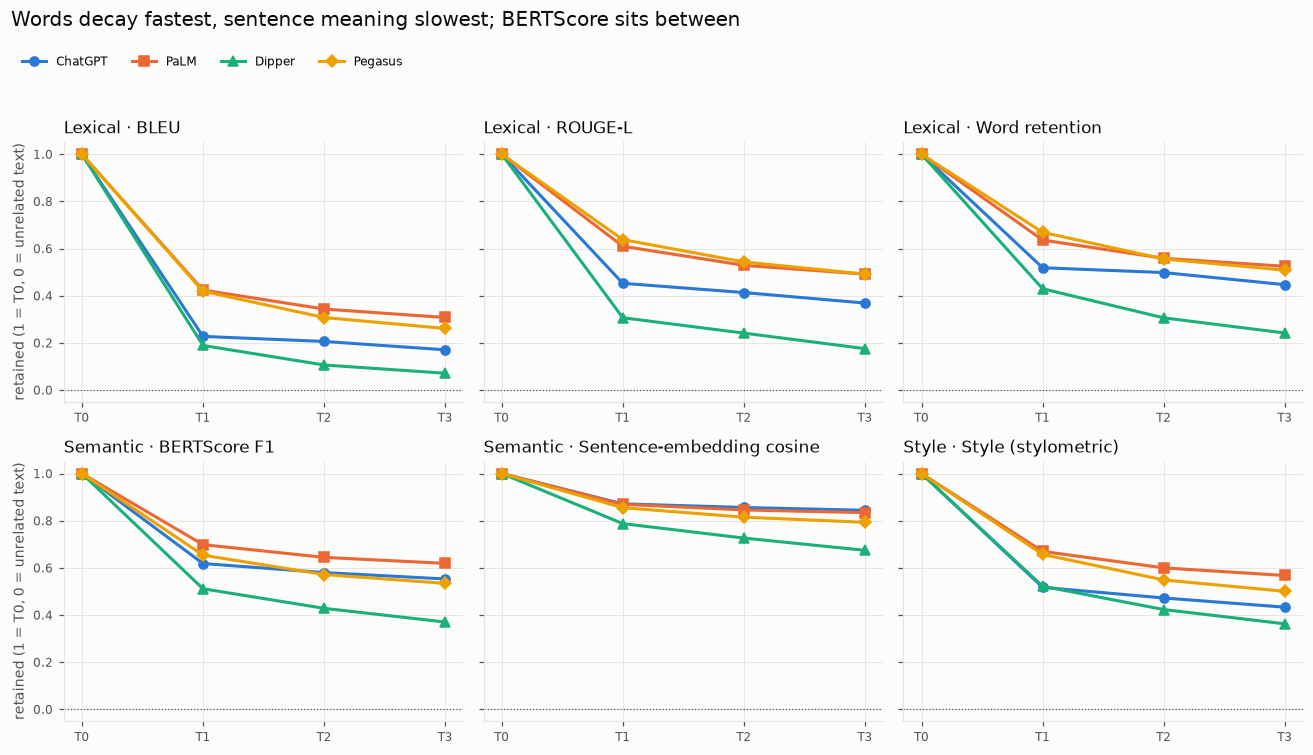

metric,bleu,rougeL,word_retention,bertscore_f,sbert_cos,style
variant,,,,,,
chatgpt,0.170,0.369,0.447,0.553,0.844,0.433
dipper,0.071,0.175,0.242,0.370,0.674,0.363
palm,0.308,0.491,0.525,0.619,0.834,0.568
pegasus(full),0.261,0.491,0.508,0.534,0.793,0.500


In [9]:
cum = scores[scores.kind == "cumulative"]
CURVE_METRICS = ["bleu", "rougeL", "word_retention", "bertscore_f", "sbert_cos", "style"]
curves = pd.concat([bootstrap_mean_ci(cum, ["variant", "round"], f"{m}_ret").assign(metric=m) for m in METRICS],
                   ignore_index=True)
curves.to_csv(OUT / "decay_curves.csv", index=False)

def plot_curves(ax, metric, variants, colors, markers=None, styles=None):
    for v in variants:
        d = curves[(curves.metric == metric) & (curves.variant == v)].sort_values("round")
        ax.fill_between([0, *d["round"]], [1, *d.ci_low], [1, *d.ci_high], color=colors[v], alpha=0.15, linewidth=0)
        ax.plot([0, *d["round"]], [1, *d["mean"]], color=colors[v], marker=(markers or {}).get(v, "o"),
                linestyle=(styles or {}).get(v, "-"), label=LABEL[v])
    ax.set_xticks([0, 1, 2, 3], ["T0", "T1", "T2", "T3"]); ax.set_title(NAME[metric], loc="left")
    ax.axhline(0, color=MUTED, linewidth=0.8, linestyle=":")

PANEL_FAMILY = {"bleu": "Lexical", "rougeL": "Lexical", "word_retention": "Lexical",
                "bertscore_f": "Semantic", "sbert_cos": "Semantic", "style": "Style"}
fig, axes = plt.subplots(2, 3, figsize=(12, 6.8), sharey=True)
for ax, m in zip(axes.flat, CURVE_METRICS):
    plot_curves(ax, m, PRIMARY, COLOR, MARKER)
    ax.set_title(f"{PANEL_FAMILY[m]} · {NAME[m]}", loc="left")
for ax in axes[:, 0]:
    ax.set_ylabel("retained (1 = T0, 0 = unrelated text)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper left", bbox_to_anchor=(0.01, 0.955), ncol=4)
fig.suptitle("Words decay fastest, sentence meaning slowest; BERTScore sits between", x=0.01, ha="left",
             fontsize=13, color=INK, y=1.0)
fig.tight_layout(rect=(0, 0, 1, 0.92))
save(fig, "decay_curves")
plt.show()
(curves[curves.metric.isin(CURVE_METRICS) & curves.variant.isin(PRIMARY) & (curves["round"] == 3)]
 .pivot(index="variant", columns="metric", values="mean")[CURVE_METRICS].round(3))

## 3. Style vs content decay: does the hull hold while the planks change?

On the retained scale, **content** = BERTScore F1 and **style** = the stylometric similarity: the mean of the per-block cosines over surface, punctuation, function-word and POS/syntax features, z-scored on reference texts. Character n-gram similarity is reported as a separate style block.

- **3.1** Style vs content vs words per paraphraser, and the decay gap (content − style) with CIs.
- **3.2** Which style features go first, and does Human style decay differently from LLM style?

decay gap = retained content - retained style (mean [95% CI]):


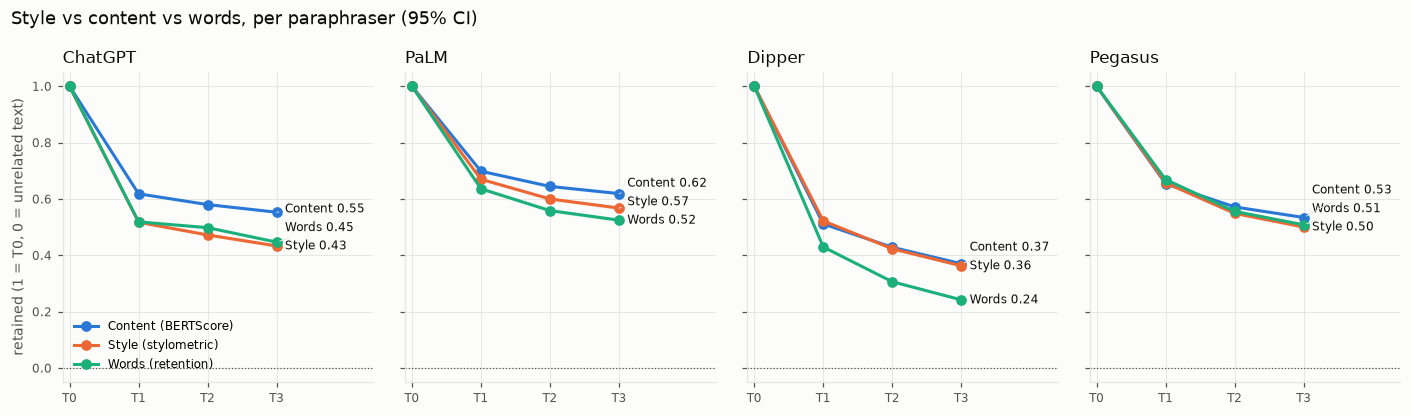

round,1,2,3
variant,,,
chatgpt,"0.101 [0.097, 0.105]","0.108 [0.104, 0.111]","0.120 [0.116, 0.124]"
dipper,"-0.011 [-0.015, -0.007]","0.005 [0.001, 0.010]","0.008 [0.004, 0.012]"
palm,"0.029 [0.026, 0.031]","0.045 [0.041, 0.048]","0.051 [0.048, 0.055]"
pegasus(full),"-0.003 [-0.006, 0.000]","0.023 [0.019, 0.027]","0.034 [0.029, 0.038]"


In [10]:
# 3.1 Style vs content per paraphraser, and the decay gap (content - style).
FAM_COLOR = {"bertscore_f": "#2a78d6", "style": "#eb6834", "word_retention": "#1baf7a"}  # 3 slots: valid all-pairs
FAM_LABEL = {"bertscore_f": "Content (BERTScore)", "style": "Style (stylometric)", "word_retention": "Words (retention)"}

fig, axes = plt.subplots(1, 4, figsize=(13, 3.8), sharey=True)
for ax, v in zip(axes, PRIMARY):
    ends = []
    for m, c in FAM_COLOR.items():
        d = curves[(curves.metric == m) & (curves.variant == v)].sort_values("round")
        ax.fill_between([0, *d["round"]], [1, *d.ci_low], [1, *d.ci_high], color=c, alpha=0.15, linewidth=0)
        ax.plot([0, *d["round"]], [1, *d["mean"]], color=c, marker="o", label=FAM_LABEL[m])
        ends.append((FAM_LABEL[m].split(" ")[0], d["mean"].iloc[-1], c))
    label_ends(ax, ends, 3, min_gap=0.065)
    ax.set_xticks([0, 1, 2, 3], ["T0", "T1", "T2", "T3"]); ax.set_xlim(-0.1, 4.4); ax.set_title(LABEL[v], loc="left")
    ax.axhline(0, color=MUTED, linewidth=0.8, linestyle=":")
axes[0].set_ylabel("retained (1 = T0, 0 = unrelated text)"); axes[0].legend(loc="lower left")
fig.suptitle("Style vs content vs words, per paraphraser (95% CI)", x=0.01, ha="left", fontsize=12, color=INK)
fig.tight_layout()

cum = cum.assign(decay_gap=cum.bertscore_f_ret - cum.style_ret)
decay_gap = bootstrap_mean_ci(cum[cum.variant.isin(PRIMARY)], ["variant", "round"], "decay_gap")
save(fig, "style_vs_content", decay_gap)
plt.show()
print("decay gap = retained content - retained style (mean [95% CI]):")
decay_gap.assign(ci=lambda d: d.apply(lambda r: f"{r['mean']:.3f} [{r.ci_low:.3f}, {r.ci_high:.3f}]", axis=1)
                 ).pivot(index="variant", columns="round", values="ci")

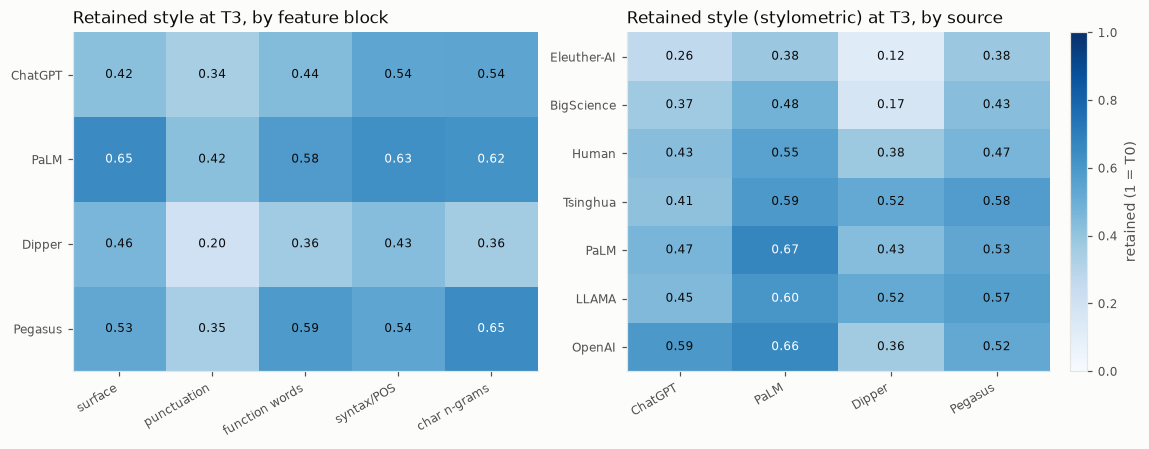

In [11]:
# 3.2 Which style features go first, and whose style decays fastest (caveat: LLM-authored originals
# begin with the Human text's opening words, their generation prompt).
BLOCK_METRICS = ["style_surface", "style_punctuation", "style_function_words", "style_syntax_pos", "style_charngram"]
t3_all = cum[(cum["round"] == 3) & cum.variant.isin(PRIMARY)]
blocks_t3 = t3_all.groupby("variant")[[f"{m}_ret" for m in BLOCK_METRICS]].mean().reindex(PRIMARY)
blocks_t3.columns = ["surface", "punctuation", "function words", "syntax/POS", "char n-grams"]
by_source = t3_all.groupby(["source", "variant"]).style_ret.mean().unstack().reindex(columns=PRIMARY)
by_source = by_source.loc[by_source.mean(axis=1).sort_values().index]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.1, 1]})
for ax, table, title in [(axes[0], blocks_t3, "Retained style at T3, by feature block"),
                         (axes[1], by_source, "Retained style (stylometric) at T3, by source")]:
    im = ax.imshow(table.to_numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")  # sequential: magnitude
    ax.set_xticks(range(table.shape[1]), [LABEL.get(c, c) for c in table.columns], rotation=30, ha="right")
    ax.set_yticks(range(table.shape[0]), [LABEL.get(i, i) for i in table.index])
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            val = table.iat[i, j]
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=8, color="white" if val > 0.6 else INK)
    ax.grid(False); ax.set_title(title, loc="left")
fig.colorbar(im, ax=axes, fraction=0.025, pad=0.02, label="retained (1 = T0)")
save(fig, "style_blocks_and_sources", by_source.reset_index())
blocks_t3.round(3).to_csv(OUT / "style_blocks_T3.csv")
plt.show()